# N-BaIoT Ablation 2: CNN + BiLSTM Only (No Transformer)

Removes the **Transformer** component. CNN output feeds directly into BiLSTM.

In [1]:
!pip install torch pandas numpy scikit-learn matplotlib seaborn tqdm --quiet

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import math
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import confusion_matrix, classification_report, f1_score, accuracy_score, precision_score, recall_score
from sklearn.neighbors import NearestNeighbors
from tqdm import tqdm

np.random.seed(42)
torch.manual_seed(42)

# ── Device: safe for Kaggle T4 / any GPU ──────────────────
if torch.cuda.is_available():
    try:
        _ = torch.zeros(1).cuda()
        device = torch.device("cuda")
        print(f"GPU: {torch.cuda.get_device_name(0)}")
    except Exception as e:
        print(f"GPU failed ({e}), using CPU.")
        device = torch.device("cpu")
else:
    device = torch.device("cpu")
print(f"Device: {device}")

GPU: Tesla T4
Device: cuda


In [5]:
CONFIG = {
    'batch_size': 512,
    'epochs': 30,
    'learning_rate': 0.001,
    'input_shape': (115, 1),
    'dataset_paths': [
        "//kaggle/input/datasets/mkashifn/nbaiot-dataset/1.benign.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.gafgyt.combo.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.gafgyt.junk.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.gafgyt.tcp.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.mirai.udp.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.mirai.scan.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.mirai.syn.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.mirai.udpplain.csv",
        "/kaggle/input/datasets/mkashifn/nbaiot-dataset/1.mirai.ack.csv",
    ],
    "labels": [
        "benign", "Gafgyt_Combo", "Gafgyt_Junk", "Gafgyt_TCP",
        "Mirai_UDP", "Mirai_Scan", "Mirai_SYN", "Mirai_UDPPlain", "Mirai_ACK",
    ],
}

SEEN_CLASSES   = ['Mirai_UDP','Mirai_SYN','Mirai_ACK','Gafgyt_TCP',
                  'Gafgyt_Combo','benign','Gafgyt_Junk','Mirai_UDPPlain']
UNSEEN_CLASSES = ['Mirai_Scan']

print(f"Seen   : {SEEN_CLASSES}")
print(f"Unseen : {UNSEEN_CLASSES}")

Seen   : ['Mirai_UDP', 'Mirai_SYN', 'Mirai_ACK', 'Gafgyt_TCP', 'Gafgyt_Combo', 'benign', 'Gafgyt_Junk', 'Mirai_UDPPlain']
Unseen : ['Mirai_Scan']


In [6]:
class IoTDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)
    def __len__(self):        return len(self.X)
    def __getitem__(self, i): return self.X[i], self.y[i]

# ── Load all CSVs ──────────────────────────────────────────
full_data = pd.DataFrame()
for i, path in enumerate(CONFIG["dataset_paths"]):
    df1 = pd.read_csv(path)
    # df2 = pd.read_csv(path.replace("1", "2"))
    df1["label"] = CONFIG["labels"][i]
    # df2["label"] = CONFIG["labels"][i]
    full_data = pd.concat([full_data, df1], ignore_index=True)

print(f"Total rows: {len(full_data)}")
print(full_data["label"].value_counts())

# ── Features & labels ─────────────────────────────────────
X_raw = full_data.drop(["label"], axis=1).values.astype(np.float32)
y_raw = full_data["label"].values

# ── Seen / Unseen split ───────────────────────────────────
seen_mask   = np.isin(y_raw, SEEN_CLASSES)
unseen_mask = np.isin(y_raw, UNSEEN_CLASSES)

X_seen, y_seen     = X_raw[seen_mask],   y_raw[seen_mask]
X_unseen, y_unseen = X_raw[unseen_mask], y_raw[unseen_mask]

# ── Encode seen labels ────────────────────────────────────
le = LabelEncoder()
y_seen_enc = le.fit_transform(y_seen)
num_classes = len(le.classes_)

X_train, X_temp, y_train, y_temp = train_test_split(
    X_seen, y_seen_enc, test_size=0.3, random_state=42, stratify=y_seen_enc)
X_val, X_test_seen, y_val, y_test_seen = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

# ── Scale (fit on train only) ─────────────────────────────
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val   = scaler.transform(X_val)
X_test_seen  = scaler.transform(X_test_seen)
X_unseen_sc  = scaler.transform(X_unseen)

# ── Build final test set (seen + unseen) ──────────────────
y_test_seen_str = le.inverse_transform(y_test_seen)
X_test_final    = np.concatenate([X_test_seen, X_unseen_sc], axis=0)
y_test_final_str= np.concatenate([y_test_seen_str, y_unseen], axis=0)

# ── Reshape to (N, Features, 1) ───────────────────────────
X_train_3d = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val_3d   = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test_3d  = X_test_final.reshape(X_test_final.shape[0], X_test_final.shape[1], 1)

y_test_dummy = np.zeros(len(X_test_3d), dtype=np.int64)

train_dataset = IoTDataset(X_train_3d, y_train)
val_dataset   = IoTDataset(X_val_3d,   y_val)
test_dataset  = IoTDataset(X_test_3d,  y_test_dummy)

# ── WeightedRandomSampler ─────────────────────────────────
class_counts     = np.bincount(y_train, minlength=num_classes)
class_weights_val= 1.0 / np.maximum(class_counts, 1)
sample_weights   = class_weights_val[y_train].astype(np.float64)
sampler = WeightedRandomSampler(weights=sample_weights, num_samples=len(sample_weights), replacement=True)

train_loader = DataLoader(train_dataset, batch_size=CONFIG['batch_size'], sampler=sampler,
                          shuffle=False, num_workers=4, pin_memory=True)
val_loader   = DataLoader(val_dataset,   batch_size=CONFIG['batch_size'],
                          shuffle=False, num_workers=4, pin_memory=True)
test_loader  = DataLoader(test_dataset,  batch_size=CONFIG['batch_size'],
                          shuffle=False, num_workers=4, pin_memory=True)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test_final)}")
print(f"Num classes: {num_classes} -> {list(le.classes_)}")

Total rows: 882575
label
Mirai_UDP         237665
Mirai_SYN         122573
Mirai_Scan        107685
Mirai_ACK         102195
Gafgyt_TCP         92141
Mirai_UDPPlain     81982
Gafgyt_Combo       59718
benign             49548
Gafgyt_Junk        29068
Name: count, dtype: int64
Train: 542423 | Val: 116233 | Test: 223919
Num classes: 8 -> ['Gafgyt_Combo', 'Gafgyt_Junk', 'Gafgyt_TCP', 'Mirai_ACK', 'Mirai_SYN', 'Mirai_UDP', 'Mirai_UDPPlain', 'benign']


In [7]:
def train_model(model, train_loader, val_loader, epochs, save_path):
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)
    optimizer = optim.Adam(model.parameters(), lr=CONFIG['learning_rate'], weight_decay=1e-4)
    history = {'accuracy': [], 'val_accuracy': [], 'loss': [], 'val_loss': []}
    best_val_acc = 0.0

    for epoch in range(epochs):
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        for inputs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs}", leave=True):
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            running_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            total  += labels.size(0)
            correct += (predicted == labels).sum().item()

        epoch_acc  = correct / total
        epoch_loss = running_loss / len(train_loader)

        model.eval()
        val_loss, val_correct, val_total = 0.0, 0, 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                val_loss    += criterion(outputs, labels).item()
                _, predicted = torch.max(outputs.data, 1)
                val_total   += labels.size(0)
                val_correct += (predicted == labels).sum().item()

        val_acc     = val_correct / val_total
        val_loss_avg= val_loss / len(val_loader)
        history['accuracy'].append(epoch_acc)
        history['loss'].append(epoch_loss)
        history['val_accuracy'].append(val_acc)
        history['val_loss'].append(val_loss_avg)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            torch.save(model.state_dict(), save_path)
            print(f"  --> Best model saved (Val Acc: {val_acc:.4f})")
        print(f"Epoch {epoch+1}: Loss={epoch_loss:.4f} | Acc={epoch_acc:.4f} | ValLoss={val_loss_avg:.4f} | ValAcc={val_acc:.4f}")

    torch.save(model.state_dict(), save_path.replace('best', 'final'))
    return history

def plot_history(history, title):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
    ax1.plot(history['loss'],      label='Train Loss')
    ax1.plot(history['val_loss'],  label='Val Loss')
    ax1.set_title(f'{title} - Loss'); ax1.legend()
    ax2.plot(history['accuracy'],     label='Train Acc')
    ax2.plot(history['val_accuracy'], label='Val Acc')
    ax2.set_title(f'{title} - Accuracy'); ax2.legend()
    plt.tight_layout()
    plt.savefig(f'{title.replace(" ","_")}_training_curves.png', dpi=150)
    plt.show()

In [8]:
class MinMaxThreeWayGate:
    def __init__(self, q=60, eps=1e-12, dist_percentile=99):
        self.q = q; self.eps = eps; self.dist_percentile = dist_percentile

    def fit(self, X_train, y_train):
        self.X_train = np.asarray(X_train, dtype=np.float32)
        self.y_train = np.asarray(y_train)
        self.classes_ = np.unique(self.y_train)
        self.class_to_idx_ = {c: i for i, c in enumerate(self.classes_)}
        C = len(self.classes_)

        self.nn_train_ = NearestNeighbors(n_neighbors=self.q + 1, metric="euclidean")
        self.nn_train_.fit(self.X_train)
        neigh_idx_train = self.nn_train_.kneighbors(self.X_train, return_distance=False)[:, 1:]

        e_train = np.zeros((self.X_train.shape[0], C), dtype=np.float32)
        for i in range(self.X_train.shape[0]):
            for c in self.y_train[neigh_idx_train[i]]:
                e_train[i, self.class_to_idx_[c]] += 1.0
        e_train /= float(self.q)
        self.e_train_ = e_train

        dists_train  = self.nn_train_.kneighbors(self.X_train, return_distance=True)[0][:, 1:]
        self.dist_tau_ = np.percentile(dists_train.mean(axis=1), self.dist_percentile)

        self.nn_test_ = NearestNeighbors(n_neighbors=self.q, metric="euclidean")
        self.nn_test_.fit(self.X_train)
        return self

    def predict_region(self, X_test):
        X_test = np.asarray(X_test, dtype=np.float32)
        C = len(self.classes_)
        dists, neigh_idx = self.nn_test_.kneighbors(X_test, return_distance=True)

        e_test = np.zeros((X_test.shape[0], C), dtype=np.float32)
        for i in range(X_test.shape[0]):
            for c in self.y_train[neigh_idx[i]]:
                e_test[i, self.class_to_idx_[c]] += 1.0
        e_test /= float(self.q)

        best_k    = e_test.argmax(axis=1)
        best_class= self.classes_[best_k]
        conf      = e_test[np.arange(X_test.shape[0]), best_k]

        reduction = np.array([self.e_train_[neigh_idx[i]][:, best_k[i]].min() for i in range(X_test.shape[0])], dtype=np.float32)
        elevation = np.array([self.e_train_[neigh_idx[i]][:, best_k[i]].max() for i in range(X_test.shape[0])], dtype=np.float32)

        inside  = (reduction >= 1.0 - self.eps) & (conf >= 1.0 - self.eps)
        support = (elevation >= 1.0 - self.eps)
        region  = np.where(inside, "inside", np.where(support, "partial", "outside"))
        region  = np.where(dists.mean(axis=1) > self.dist_tau_, "outside", region)
        return best_class, region, conf

def get_prob_features(model, loader, device, temperature=1.0):
    model.eval()
    feats, labels = [], []
    with torch.no_grad():
        for inputs, y in loader:
            inputs = inputs.to(device)
            probs  = torch.softmax(model(inputs) / temperature, dim=1)
            feats.append(probs.cpu().numpy())
            labels.append(y.numpy())
    return np.concatenate(feats), np.concatenate(labels)

def predict_minmax_3labels(model, loader, gate, le, device, temperature=1.0):
    model.eval()
    preds = []
    with torch.no_grad():
        for inputs, _ in loader:
            inputs = inputs.to(device)
            probs  = torch.softmax(model(inputs) / temperature, dim=1).cpu().numpy()
            best_class_idx, region, _ = gate.predict_region(probs)
            for k_idx, r in zip(best_class_idx, region):
                preds.append(le.inverse_transform([k_idx])[0] if r == "inside" else "Emerging")
    return np.array(preds)

In [9]:
def evaluate_model(model, test_loader, gate, le, y_test_final_str, model_name):
    print(f"\n{'='*60}")
    print(f"  EVALUATION: {model_name}")
    print(f"{'='*60}")

    y_pred = predict_minmax_3labels(model, test_loader, gate, le, device, temperature=1.0)

    # ── Exclude 'Emerging' from metrics and confusion matrix ────────
    mask = (np.array(y_pred) != "Emerging") & (np.array(y_test_final_str) != "Emerging")
    y_true_f = np.array(y_test_final_str)[mask]
    y_pred_f = np.array(y_pred)[mask]

    print(f"\n  Total test samples  : {len(y_test_final_str)}")
    print(f"  Predicted Emerging  : {int((np.array(y_pred)=='Emerging').sum())} (excluded from metrics)")
    print(f"  Evaluated samples   : {int(mask.sum())}")

    all_classes = sorted(list(set(y_true_f) | set(y_pred_f)))

    acc  = accuracy_score(y_true_f, y_pred_f)
    prec = precision_score(y_true_f, y_pred_f, average='weighted', zero_division=0)
    rec  = recall_score(y_true_f, y_pred_f, average='weighted', zero_division=0)
    f1   = f1_score(y_true_f, y_pred_f, average='weighted', zero_division=0)

    print(f"\n  Accuracy : {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall   : {rec:.4f}")
    print(f"  F1-Score : {f1:.4f}")
    print("\n  Classification Report (Emerging excluded):")
    print(classification_report(y_true_f, y_pred_f, zero_division=0))

    # Confusion Matrix
    cm = confusion_matrix(y_true_f, y_pred_f, labels=all_classes)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=all_classes, yticklabels=all_classes)
    plt.title(f'Confusion Matrix - {model_name}\n(Emerging excluded)')
    plt.ylabel('True Label'); plt.xlabel('Predicted Label')
    plt.xticks(rotation=45, ha='right'); plt.yticks(rotation=0)
    plt.tight_layout()
    plt.savefig(f'{model_name.replace(" ","_")}_confusion_matrix.png', dpi=150)
    plt.show()

    return {'model': model_name, 'accuracy': acc, 'precision': prec, 'recall': rec, 'f1': f1}

In [10]:
# ============================================================
# ABLATION 2: CNN + BiLSTM Only  (No Transformer)
# Identical to full model except Transformer is removed.
# CNN output feeds directly into BiLSTM.
# ============================================================

class CNNBiLSTMOnly(nn.Module):
    """
    Ablation: Removes Transformer.
    CNN -> BiLSTM -> Classifier
    """
    def __init__(self, input_len, num_classes):
        super().__init__()
        # CNN  (same as full model)
        self.conv1   = nn.Conv1d(1,   128, kernel_size=3, padding=1)
        self.relu    = nn.ReLU()
        self.pool    = nn.MaxPool1d(kernel_size=2)
        self.conv2   = nn.Conv1d(128, 256, kernel_size=3, padding=1)
        # BiLSTM  (same as full model, no Transformer before it)
        self.lstm    = nn.LSTM(input_size=256, hidden_size=64,
                               bidirectional=True, batch_first=True)
        # Classifier  (same as full model)
        self.fc1     = nn.Linear(64*2, 64)
        self.dropout = nn.Dropout(0.3)
        self.fc_out  = nn.Linear(64, num_classes)

    def forward(self, x):
        x = x.permute(0, 2, 1)           # (B,1,F)
        x = self.relu(self.conv1(x))      # (B,128,F)
        x = self.pool(x)                  # (B,128,F/2)
        x = self.relu(self.conv2(x))      # (B,256,F/2)
        x = x.permute(0, 2, 1)           # (B,F/2,256)  — no Transformer
        _, (h_n, _) = self.lstm(x)        # h_n: (2,B,64)
        x = torch.cat((h_n[-2], h_n[-1]), dim=1)  # (B,128)
        x = self.relu(self.fc1(x))
        x = self.dropout(x)
        return self.fc_out(x)

INPUT_DIM = CONFIG['input_shape'][0]
model_no_transformer = CNNBiLSTMOnly(INPUT_DIM, num_classes).to(device)
print(f"CNN+BiLSTM (No Transformer) | params: {sum(p.numel() for p in model_no_transformer.parameters() if p.requires_grad):,}")
print(model_no_transformer)

CNN+BiLSTM (No Transformer) | params: 272,712
CNNBiLSTMOnly(
  (conv1): Conv1d(1, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu): ReLU()
  (pool): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(128, 256, kernel_size=(3,), stride=(1,), padding=(1,))
  (lstm): LSTM(256, 64, batch_first=True, bidirectional=True)
  (fc1): Linear(in_features=128, out_features=64, bias=True)
  (dropout): Dropout(p=0.3, inplace=False)
  (fc_out): Linear(in_features=64, out_features=8, bias=True)
)


Training CNN+BiLSTM (No Transformer)...


Epoch 1/30: 100%|██████████| 1060/1060 [00:31<00:00, 34.02it/s]


  --> Best model saved (Val Acc: 0.9724)
Epoch 1: Loss=0.7002 | Acc=0.8798 | ValLoss=0.5166 | ValAcc=0.9724


Epoch 2/30: 100%|██████████| 1060/1060 [00:29<00:00, 36.24it/s]


  --> Best model saved (Val Acc: 0.9945)
Epoch 2: Loss=0.5877 | Acc=0.9533 | ValLoss=0.4810 | ValAcc=0.9945


...

Epoch 28: Loss=0.4965 | Acc=0.9974 | ValLoss=0.4708 | ValAcc=0.9982


Epoch 29/30: 100%|██████████| 1060/1060 [00:30<00:00, 34.67it/s]


Epoch 29: Loss=0.5020 | Acc=0.9950 | ValLoss=0.4707 | ValAcc=0.9991


Epoch 30/30: 100%|██████████| 1060/1060 [00:30<00:00, 34.61it/s]


Epoch 30: Loss=0.5019 | Acc=0.9949 | ValLoss=0.5913 | ValAcc=0.9768


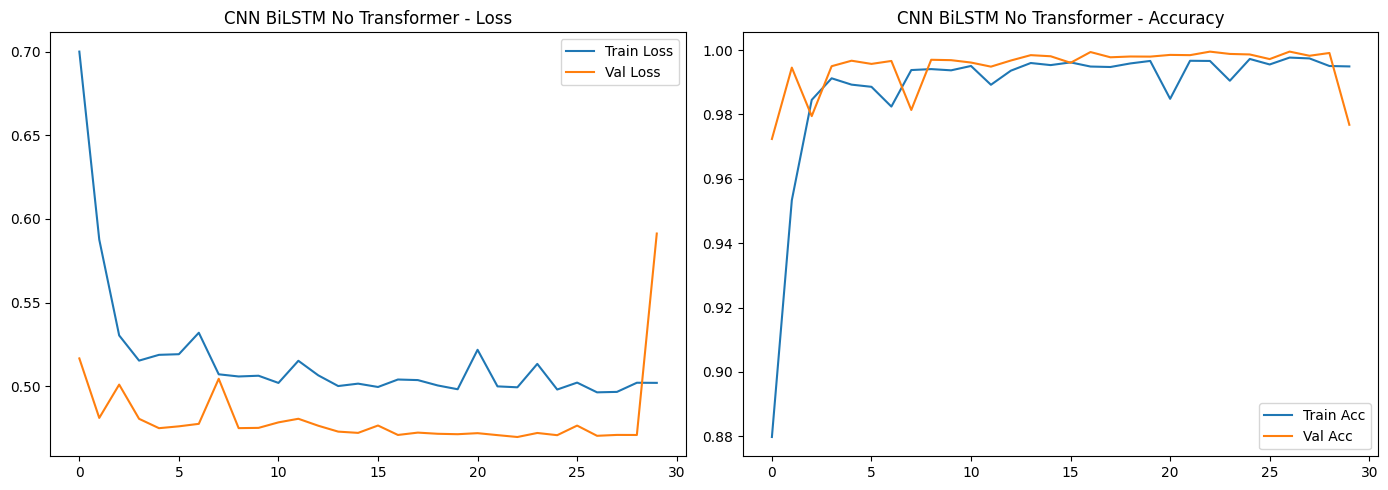

In [11]:
print("Training CNN+BiLSTM (No Transformer)...")
history_nt = train_model(model_no_transformer, train_loader, val_loader,
                          CONFIG['epochs'], save_path='nbaiot_no_transformer_best.pth')
plot_history(history_nt, "CNN BiLSTM No Transformer")

In [12]:
print("Fitting MinMax Gate for CNN+BiLSTM (No Transformer)...")
train_feats_nt, train_labels_nt = get_prob_features(model_no_transformer, train_loader, device)
gate_nt = MinMaxThreeWayGate(q=7).fit(train_feats_nt, train_labels_nt)
print(f"Gate fitted | feats: {train_feats_nt.shape}")

Fitting MinMax Gate for CNN+BiLSTM (No Transformer)...
Gate fitted | feats: (542423, 8)



  EVALUATION: CNN + BiLSTM (No Transformer)

  Total test samples  : 223919
  Predicted Emerging  : 110299 (excluded from metrics)
  Evaluated samples   : 113620

  Accuracy : 0.9938
  Precision: 0.9886
  Recall   : 0.9938
  F1-Score : 0.9911

  Classification Report (Emerging excluded):
                precision    recall  f1-score   support

  Gafgyt_Combo       1.00      1.00      1.00      8748
   Gafgyt_Junk       1.00      1.00      1.00      4181
    Gafgyt_TCP       1.00      1.00      1.00     13810
     Mirai_ACK       1.00      1.00      1.00     14837
     Mirai_SYN       1.00      1.00      1.00     18324
    Mirai_Scan       0.00      0.00      0.00       644
     Mirai_UDP       1.00      1.00      1.00     33579
Mirai_UDPPlain       1.00      1.00      1.00     12095
        benign       0.92      1.00      0.96      7402

      accuracy                           0.99    113620
     macro avg       0.88      0.89      0.88    113620
  weighted avg       0.99      0.99 

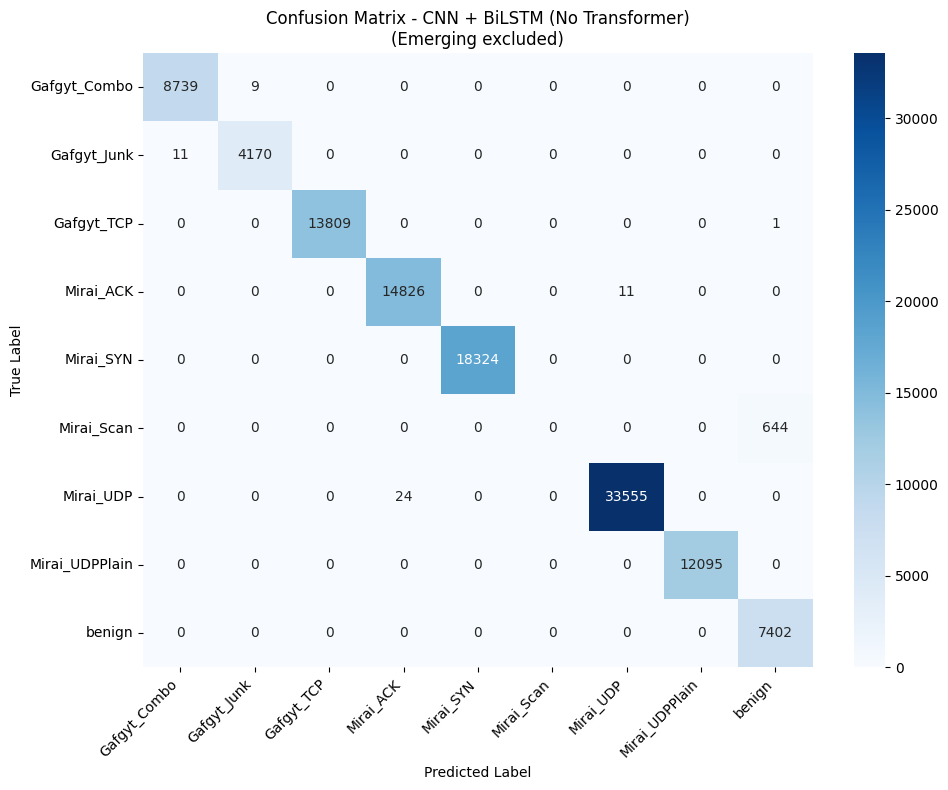

In [13]:
results_nt = evaluate_model(model_no_transformer, test_loader, gate_nt, le,
                             y_test_final_str, "CNN + BiLSTM (No Transformer)")